

**Q2. Portfolio Construction**

**(a) First Dates Stocks Start to Have Return Data**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('crsp_sample2.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['permno','date'])

# handle missing data
df['ret'] = df['ret'].fillna(0)

# first return date
launch_dates = df.groupby('permno')['date'].min()

print(launch_dates)

permno
11601   2012-01-03
13610   2010-01-04
39731   2010-01-04
79089   2010-01-04
83148   2010-01-04
85459   2010-01-04
86091   2010-01-04
89509   2010-01-04
90029   2010-01-04
91421   2010-01-04
Name: date, dtype: datetime64[ns]


**(b) Monthly Reallocation Equal-Weighted Index**

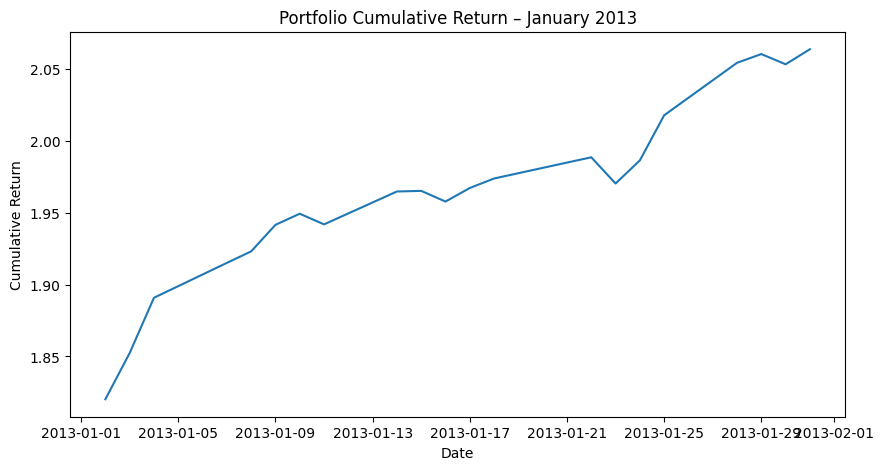

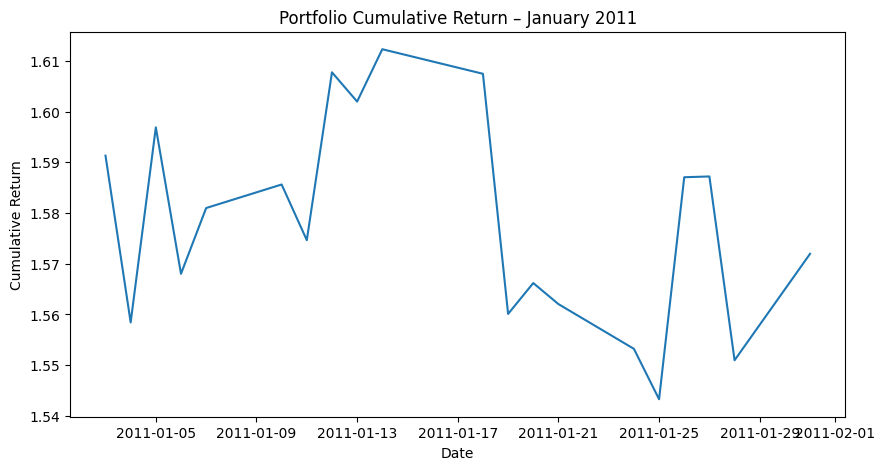

In [3]:
df['month'] = df['date'].dt.to_period('M')
df['n_active'] = df.groupby('date')['permno'].transform('count')
df['weight_eq'] = 1 / df['n_active']
df['weighted_ret'] = df['weight_eq'] * df['ret']
daily_index = df.groupby('date')['weighted_ret'].sum()
cum_index = (1 + daily_index).cumprod()

plt.figure(figsize=(10,5))
plt.plot(cum_index['2013-01'])
plt.title('Portfolio Cumulative Return – January 2013')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.show()

plt.figure(figsize=(10,5))
plt.plot(cum_index['2011-01'])
plt.title('Portfolio Cumulative Return – January 2011')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.show()